# Three-dimensional phase speeds in a cubic crystal

Each direction solves the full 3 × 3 Christoffel eigenproblem with OneSimulation. Change C44, density or the branch, then compare the surface with its planar section. C11=166 and C12=64 GPa. At C44=51 GPa the three surfaces become spheres. Phase velocity and energy-flow direction differ in anisotropic media.

In [1]:
"""Three-dimensional acoustic phase-speed surfaces from OneSimulation eigenproblems.

Run in an activated OneSimulation environment. Units: Cij in GPa, density kg/m^3,
output speed km/s. A radius v(n) in direction n is a phase-speed surface, not a
point-source wavefront: energy need not travel parallel to n in an anisotropic solid.
"""
import argparse
import numpy as np
import matplotlib.pyplot as plt
from onesim.numerics.linear.matrices.dense_linear_algebra import symmetric_eigenvalues


def speeds(direction, c44=80., density=2330.):
    n = np.asarray(direction, dtype=float)
    n = n / np.linalg.norm(n)
    gamma = (64. + c44) * np.outer(n, n)
    gamma += np.diag(c44 + (102. - 2*c44) * n**2)
    return np.sqrt(symmetric_eigenvalues(gamma) * 1e9 / density) / 1000


def run(c44=80., density=2330., branch=2):
    if not 30 <= c44 <= 110 or not 1800 <= density <= 9000 or branch not in (0, 1, 2):
        raise ValueError('Use the same stable parameter ranges as the browser controls.')
    theta, phi = np.meshgrid(np.linspace(0, np.pi, 37), np.linspace(0, 2*np.pi, 73), indexing='ij')
    directions = np.stack([np.sin(theta)*np.cos(phi), np.sin(theta)*np.sin(phi), np.cos(theta)], axis=-1)
    velocity = np.array([speeds(n, c44, density) for n in directions.reshape(-1, 3)]).reshape(*theta.shape, 3)
    radius = velocity[:, :, branch]
    x, y, z = np.moveaxis(directions * radius[:, :, None], -1, 0)
    for label, n in [('[100]', [1, 0, 0]), ('[110]', [1, 1, 0]), ('[111]', [1, 1, 1])]:
        print(label, ' '.join(f'{v:.6f}' for v in speeds(n, c44, density)), 'km/s')
    print(f'Branch {branch} radius range: {radius.min():.6f} to {radius.max():.6f} km/s')
    # An independent analytic limit is isotropy, C44=(C11-C12)/2=51 GPa.
    isotropic = np.array([speeds(n, 51, density) for n in directions[::6, ::12].reshape(-1, 3)])
    expected = np.sqrt(np.array([51., 51., 166.]) * 1000 / density)
    assert np.max(np.abs(isotropic - expected)) < 1e-11
    print('Isotropic directional invariance: verified')
    fig = plt.figure(figsize=(10, 4.5), layout='constrained')
    spatial = fig.add_subplot(1, 2, 1, projection='3d')
    spatial.plot_surface(x, y, z, cmap='viridis', linewidth=.15, edgecolor='#46605e', alpha=.95)
    limit = radius.max()
    spatial.set(xlabel='vx (km/s)', ylabel='vy (km/s)', zlabel='vz (km/s)',
                xlim=(-limit, limit), ylim=(-limit, limit), zlim=(-limit, limit),
                title=['Slow', 'Middle', 'Fast'][branch] + ' phase-speed surface')
    spatial.set_box_aspect((1, 1, 1))
    planar = fig.add_subplot(1, 2, 2)
    angle = np.linspace(0, np.pi/2, 181)
    values = np.array([speeds([np.cos(t), np.sin(t), 0], c44, density) for t in angle])
    for i, label in enumerate(['Slow', 'Middle', 'Fast']):
        planar.plot(np.degrees(angle), values[:, i], label=label)
    planar.set(xlabel='Direction [100] to [010] (degrees)', ylabel='Phase speed (km/s)', title='(001) planar section')
    planar.legend(); planar.grid(alpha=.2)
    fig.savefig('physics-cubic-surface.png', dpi=165)
    return directions, velocity




[100] 5.859587 5.859587 8.440654 km/s
[110] 4.678505 5.859587 9.148278 km/s
[111] 5.102666 5.102666 9.372287 km/s
Branch 2 radius range: 8.440654 to 9.372255 km/s
Isotropic directional invariance: verified


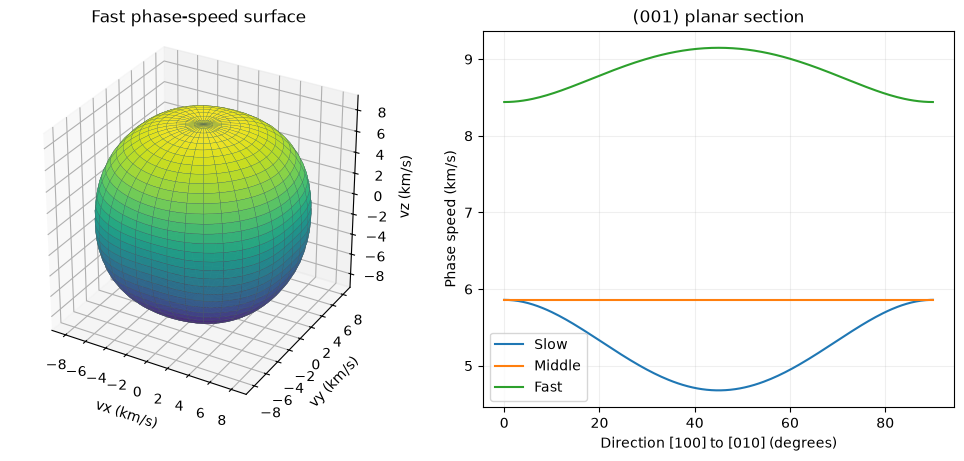

In [2]:
directions, velocities = run(c44=80., density=2330., branch=2)
plt.show()